# Minería de Datos
## Análisis de factores relacionados con el rendimiento académico

**Pregunta de negocio:** ¿Qué factores académicos, familiares y de comportamiento pueden ayudar a reconocer a los estudiantes que podrían necesitar acompañamiento para mejorar su rendimiento?

**Bases utilizadas:** para desarrollar el análisis trabajé con los dos archivos del conjunto *Student Performance* de UCI: `student-mat.csv` (Matemáticas) y `student-por.csv` (Portugués). Matemáticas contiene 395 registros y Portugués 649. Los dos archivos se analizan por separado y luego se comparan sus resultados generales. No uno las filas entre sí, porque los archivos no incluyen un identificador personal común que permita asegurar que una fila de Matemáticas y otra de Portugués correspondan al mismo estudiante.

**Criterio de bajo rendimiento:** para poder comparar los resultados, considero que hay bajo rendimiento cuando la calificación final `G3` es menor que 10, en una escala de 0 a 20. Este es un criterio operativo para el proyecto; no reemplaza las reglas de evaluación de una institución educativa.

**Fuente:** Cortez, P. (2008). *Student Performance* [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5TG7T


## Preparación y carga de las bases de datos

En esta práctica voy a trabajar con los dos archivos. Cuando Colab abra la ventana para subir archivos, selecciona `student-mat.csv` y `student-por.csv`. También se aceptan nombres descargados con sufijos, por ejemplo `student-mat(6).csv` o `student-por(6).csv`.

Cada base se mantiene independiente para no asumir que los registros de ambos archivos pertenecen a las mismas personas.


In [1]:
from google.colab import files
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Subir los dos archivos del proyecto.
uploaded = files.upload()

# Buscar los archivos por el inicio del nombre para aceptar copias con sufijos.
candidatos_mat = [
    nombre for nombre in uploaded.keys()
    if nombre.lower().startswith("student-mat") and nombre.lower().endswith(".csv")
]
candidatos_por = [
    nombre for nombre in uploaded.keys()
    if nombre.lower().startswith("student-por") and nombre.lower().endswith(".csv")
]

if not candidatos_mat or not candidatos_por:
    raise FileNotFoundError(
        "Debes subir los dos archivos: student-mat.csv y student-por.csv. "
        "También se aceptan nombres como student-mat(6).csv y student-por(6).csv."
    )

# Si está el nombre original, se prefiere; de lo contrario se usa el archivo encontrado.
archivo_mat = next(
    (nombre for nombre in candidatos_mat if nombre.lower() == "student-mat.csv"),
    candidatos_mat[0]
)
archivo_por = next(
    (nombre for nombre in candidatos_por if nombre.lower() == "student-por.csv"),
    candidatos_por[0]
)

mat = pd.read_csv(archivo_mat, sep=";")
por = pd.read_csv(archivo_por, sep=";")

# Los sufijos permiten distinguir las columnas de cada asignatura.
datos = mat.add_suffix("_mat").copy()
datos_por = por.add_suffix("_por").copy()

bases = {
    "Matemáticas": (datos, "mat"),
    "Portugués": (datos_por, "por")
}

print("Archivo de Matemáticas:", archivo_mat)
print("Archivo de Portugués:", archivo_por)
print("Registros de Matemáticas:", len(datos))
print("Registros de Portugués:", len(datos_por))
print("Las bases se mantienen separadas; no se realiza un cruce de estudiantes.")

display(pd.DataFrame({
    "Asignatura": ["Matemáticas", "Portugués"],
    "Registros": [len(datos), len(datos_por)],
    "Columnas": [datos.shape[1], datos_por.shape[1]]
}))
display(datos.head())
display(datos_por.head())


Saving student-mat.csv to student-mat.csv
Saving student-por.csv to student-por.csv
Archivo de Matemáticas: student-mat.csv
Archivo de Portugués: student-por.csv
Registros de Matemáticas: 395
Registros de Portugués: 649
Las bases se mantienen separadas; no se realiza un cruce de estudiantes.


,Asignatura,Registros,Columnas
0,Matemáticas,395,33
1,Portugués,649,33


,school_mat,sex_mat,age_mat,address_mat,famsize_mat,Pstatus_mat,Medu_mat,Fedu_mat,Mjob_mat,Fjob_mat,...,famrel_mat,freetime_mat,goout_mat,Dalc_mat,Walc_mat,health_mat,absences_mat,G1_mat,G2_mat,G3_mat
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


,school_por,sex_por,age_por,address_por,famsize_por,Pstatus_por,Medu_por,Fedu_por,Mjob_por,Fjob_por,...,famrel_por,freetime_por,goout_por,Dalc_por,Walc_por,health_por,absences_por,G1_por,G2_por,G3_por
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,4,0,11,11
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,2,9,11,11
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,6,12,13,12
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,0,14,14,14
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,0,11,13,13


## 1. Calidad de los datos

Primero reviso cada archivo por separado. Compruebo los tipos de datos, los valores faltantes, los registros repetidos y los rangos de las variables principales. Si un dato necesita cambiar de tipo, lo convierto; si aparece un valor extraño, lo reviso antes de decidir qué hacer. No elimino registros de forma automática.


In [2]:
variables_numericas_base = [
    "age", "Medu", "Fedu", "traveltime", "studytime", "failures",
    "famrel", "freetime", "goout", "Dalc", "Walc", "health",
    "absences", "G1", "G2", "G3"
]

for asignatura, (base, sufijo) in bases.items():
    print("\n" + "=" * 65)
    print(f"REVISIÓN DE CALIDAD: {asignatura.upper()}")
    print("=" * 65)

    variables_numericas = [f"{col}_{sufijo}" for col in variables_numericas_base]
    columnas_convertidas = []

    for columna in variables_numericas:
        tipo_anterior = base[columna].dtype
        base[columna] = pd.to_numeric(base[columna], errors="coerce")
        tipo_actual = base[columna].dtype
        if tipo_actual != tipo_anterior:
            columnas_convertidas.append((columna, str(tipo_anterior), str(tipo_actual)))

    if columnas_convertidas:
        print("Columnas cuyo tipo cambió:")
        display(pd.DataFrame(
            columnas_convertidas,
            columns=["Columna", "Tipo anterior", "Tipo actual"]
        ))
    else:
        print("Las variables numéricas ya estaban en un formato adecuado; no fue necesario convertirlas.")

    print("\nInformación general")
    base.info()
    print("\nTipos de datos")
    display(base.dtypes.to_frame("tipo"))
    print("\nValores nulos por columna")
    display(base.isnull().sum().to_frame("valores_nulos"))
    print("Total de valores nulos:", int(base.isnull().sum().sum()))
    print("Registros duplicados completos:", int(base.duplicated().sum()))
    print("\nEstadísticas descriptivas")
    display(base[variables_numericas].describe().round(2))



REVISIÓN DE CALIDAD: MATEMÁTICAS
Las variables numéricas ya estaban en un formato adecuado; no fue necesario convertirlas.

Información general
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   school_mat      395 non-null    object
 1   sex_mat         395 non-null    object
 2   age_mat         395 non-null    int64 
 3   address_mat     395 non-null    object
 4   famsize_mat     395 non-null    object
 5   Pstatus_mat     395 non-null    object
 6   Medu_mat        395 non-null    int64 
 7   Fedu_mat        395 non-null    int64 
 8   Mjob_mat        395 non-null    object
 9   Fjob_mat        395 non-null    object
 10  reason_mat      395 non-null    object
 11  guardian_mat    395 non-null    object
 12  traveltime_mat  395 non-null    int64 
 13  studytime_mat   395 non-null    int64 
 14  failures_mat    395 non-null    int64 
 1

,tipo
school_mat,object
sex_mat,object
age_mat,int64
address_mat,object
famsize_mat,object
Pstatus_mat,object
Medu_mat,int64
Fedu_mat,int64
Mjob_mat,object
Fjob_mat,object



Valores nulos por columna


,valores_nulos
school_mat,0
sex_mat,0
age_mat,0
address_mat,0
famsize_mat,0
Pstatus_mat,0
Medu_mat,0
Fedu_mat,0
Mjob_mat,0
Fjob_mat,0


Total de valores nulos: 0
Registros duplicados completos: 0

Estadísticas descriptivas


,age_mat,Medu_mat,Fedu_mat,traveltime_mat,studytime_mat,failures_mat,famrel_mat,freetime_mat,goout_mat,Dalc_mat,Walc_mat,health_mat,absences_mat,G1_mat,G2_mat,G3_mat
count,395.00,395.00,395.00,395.00,395.00,395.00,395.00,395.00,395.00,395.00,395.00,395.00,395.00,395.00,395.00,395.00
mean,16.70,2.75,2.52,1.45,2.04,0.33,3.94,3.24,3.11,1.48,2.29,3.55,5.71,10.91,10.71,10.42
std,1.28,1.09,1.09,0.70,0.84,0.74,0.90,1.00,1.11,0.89,1.29,1.39,8.00,3.32,3.76,4.58
min,15.00,0.00,0.00,1.00,1.00,0.00,1.00,1.00,1.00,1.00,1.00,1.00,0.00,3.00,0.00,0.00
25%,16.00,2.00,2.00,1.00,1.00,0.00,4.00,3.00,2.00,1.00,1.00,3.00,0.00,8.00,9.00,8.00
50%,17.00,3.00,2.00,1.00,2.00,0.00,4.00,3.00,3.00,1.00,2.00,4.00,4.00,11.00,11.00,11.00
75%,18.00,4.00,3.00,2.00,2.00,0.00,5.00,4.00,4.00,2.00,3.00,5.00,8.00,13.00,13.00,14.00
max,22.00,4.00,4.00,4.00,4.00,3.00,5.00,5.00,5.00,5.00,5.00,5.00,75.00,19.00,19.00,20.00


... (2 outputs left out)


Valores nulos por columna


,valores_nulos
school_por,0
sex_por,0
age_por,0
address_por,0
famsize_por,0
Pstatus_por,0
Medu_por,0
Fedu_por,0
Mjob_por,0
Fjob_por,0


Total de valores nulos: 0
Registros duplicados completos: 0

Estadísticas descriptivas


,age_por,Medu_por,Fedu_por,traveltime_por,studytime_por,failures_por,famrel_por,freetime_por,goout_por,Dalc_por,Walc_por,health_por,absences_por,G1_por,G2_por,G3_por
count,649.00,649.00,649.00,649.00,649.00,649.00,649.00,649.00,649.00,649.00,649.00,649.00,649.00,649.00,649.00,649.00
mean,16.74,2.51,2.31,1.57,1.93,0.22,3.93,3.18,3.18,1.50,2.28,3.54,3.66,11.40,11.57,11.91
std,1.22,1.13,1.10,0.75,0.83,0.59,0.96,1.05,1.18,0.92,1.28,1.45,4.64,2.75,2.91,3.23
min,15.00,0.00,0.00,1.00,1.00,0.00,1.00,1.00,1.00,1.00,1.00,1.00,0.00,0.00,0.00,0.00
25%,16.00,2.00,1.00,1.00,1.00,0.00,4.00,3.00,2.00,1.00,1.00,2.00,0.00,10.00,10.00,10.00
50%,17.00,2.00,2.00,1.00,2.00,0.00,4.00,3.00,3.00,1.00,2.00,4.00,2.00,11.00,11.00,12.00
75%,18.00,4.00,3.00,2.00,2.00,0.00,5.00,4.00,4.00,2.00,3.00,5.00,6.00,13.00,13.00,14.00
max,22.00,4.00,4.00,4.00,4.00,3.00,5.00,5.00,5.00,5.00,5.00,5.00,32.00,19.00,19.00,19.00


### Revisión de rangos y consistencia

Según la documentación del conjunto, las calificaciones `G1`, `G2` y `G3` deben estar entre 0 y 20, mientras que las ausencias se registran entre 0 y 93. Reviso estos límites en Matemáticas y Portugués. Si alguna fila queda por fuera, la dejo identificada para contrastarla con el archivo original antes de corregirla o excluirla.


In [3]:
for asignatura, (base, sufijo) in bases.items():
    print("\n" + "=" * 60)
    print(f"VALIDACIÓN DE RANGOS: {asignatura.upper()}")
    print("=" * 60)

    columnas_notas = [f"G1_{sufijo}", f"G2_{sufijo}", f"G3_{sufijo}"]
    mascara_notas_invalidas = (
        base[columnas_notas].lt(0).any(axis=1) |
        base[columnas_notas].gt(20).any(axis=1)
    )
    notas_fuera_rango = base.loc[mascara_notas_invalidas, columnas_notas]

    columna_ausencias = f"absences_{sufijo}"
    mascara_ausencias_invalidas = (
        (base[columna_ausencias] < 0) |
        (base[columna_ausencias] > 93)
    )
    ausencias_fuera_rango = base.loc[mascara_ausencias_invalidas, [columna_ausencias]]

    print("Registros con alguna nota fuera de 0–20:", len(notas_fuera_rango))
    display(notas_fuera_rango)
    print("Registros con ausencias fuera de 0–93:", len(ausencias_fuera_rango))
    display(ausencias_fuera_rango)

    if notas_fuera_rango.empty and ausencias_fuera_rango.empty:
        print("Resultado: no se encontraron registros fuera de los rangos revisados.")
    else:
        print("Resultado: hay registros que requieren revisión contra la fuente original antes de tomar una decisión.")



VALIDACIÓN DE RANGOS: MATEMÁTICAS
Registros con alguna nota fuera de 0–20: 0


,G1_mat,G2_mat,G3_mat


Registros con ausencias fuera de 0–93: 0


,absences_mat


Resultado: no se encontraron registros fuera de los rangos revisados.

VALIDACIÓN DE RANGOS: PORTUGUÉS
Registros con alguna nota fuera de 0–20: 0


,G1_por,G2_por,G3_por


Registros con ausencias fuera de 0–93: 0


,absences_por


Resultado: no se encontraron registros fuera de los rangos revisados.
Error: Runtime no longer has a reference to this dataframe, please re-run this cell and try again.


### Identificación y tratamiento de valores atípicos

Para revisar los valores extremos utilizo el rango intercuartílico (IQR). Aplico el mismo procedimiento a las ausencias y a la calificación final de cada asignatura, pero calculo los límites por separado porque Matemáticas y Portugués tienen distribuciones distintas.

Que un registro aparezca como atípico no significa que esté mal diligenciado. Por eso, los casos se marcan y se conservan mientras estén dentro de los rangos documentados. La siguiente celda muestra los límites y la cantidad de casos encontrados en cada variable; si se cambia alguno de los archivos, los resultados se vuelven a calcular.


In [4]:
def detectar_atipicos(data, columna):
    q1 = data[columna].quantile(0.25)
    q3 = data[columna].quantile(0.75)
    iqr = q3 - q1
    limite_inferior = q1 - 1.5 * iqr
    limite_superior = q3 + 1.5 * iqr

    mascara = (data[columna] < limite_inferior) | (data[columna] > limite_superior)
    atipicos = data.loc[mascara, [columna]].copy()
    atipicos.insert(0, "indice_original", atipicos.index)

    print(f"\nVariable: {columna}")
    print(f"Q1: {q1:.2f} | Q3: {q3:.2f} | IQR: {iqr:.2f}")
    print(f"Límite inferior: {limite_inferior:.2f}")
    print(f"Límite superior: {limite_superior:.2f}")
    print(f"Cantidad de valores atípicos: {len(atipicos)}")
    display(atipicos)
    return atipicos

atipicos = {}
for asignatura, (base, sufijo) in bases.items():
    print("\n" + "=" * 60)
    print(f"VALORES ATÍPICOS: {asignatura.upper()}")
    print("=" * 60)

    columna_ausencias = f"absences_{sufijo}"
    columna_g3 = f"G3_{sufijo}"
    atipicos_aus = detectar_atipicos(base, columna_ausencias)
    atipicos_g3 = detectar_atipicos(base, columna_g3)

    # Se crean marcas para localizar los casos, sin borrar ni cambiar sus valores.
    base["marca_atipico_ausencias"] = base.index.isin(atipicos_aus["indice_original"])
    base["marca_atipico_G3"] = base.index.isin(atipicos_g3["indice_original"])

    atipicos[asignatura] = {
        "ausencias": atipicos_aus,
        "G3": atipicos_g3
    }

    print("Registros marcados por ausencias:", int(base["marca_atipico_ausencias"].sum()))
    print("Registros marcados por G3:", int(base["marca_atipico_G3"].sum()))



VALORES ATÍPICOS: MATEMÁTICAS

Variable: absences_mat
Q1: 0.00 | Q3: 8.00 | IQR: 8.00
Límite inferior: -12.00
Límite superior: 20.00
Cantidad de valores atípicos: 15


,indice_original,absences_mat
40,40,25
74,74,54
103,103,26
183,183,56
198,198,24
205,205,28
216,216,22
260,260,21
276,276,75
277,277,22



Variable: G3_mat
Q1: 8.00 | Q3: 14.00 | IQR: 6.00
Límite inferior: -1.00
Límite superior: 23.00
Cantidad de valores atípicos: 0


,indice_original,G3_mat


Registros marcados por ausencias: 15
Registros marcados por G3: 0

VALORES ATÍPICOS: PORTUGUÉS

Variable: absences_por
Q1: 0.00 | Q3: 6.00 | IQR: 6.00
Límite inferior: -9.00
Límite superior: 15.00
Cantidad de valores atípicos: 21


,indice_original,absences_por
40,40,16
103,103,16
150,150,24
155,155,22
161,161,16
197,197,32
206,206,16
211,211,16
212,212,30
217,217,21



Variable: G3_por
Q1: 10.00 | Q3: 14.00 | IQR: 4.00
Límite inferior: 4.00
Límite superior: 20.00
Cantidad de valores atípicos: 16


,indice_original,G3_por
163,163,0
172,172,1
440,440,0
519,519,0
563,563,0
567,567,0
583,583,0
586,586,0
597,597,0
603,603,0


Registros marcados por ausencias: 21
Registros marcados por G3: 16


## 2. Análisis exploratorio de datos (EDA)

En esta parte reviso cómo se comportan las calificaciones, las ausencias, el tiempo de estudio y los antecedentes de reprobación. Hago el análisis por separado para Matemáticas y Portugués, y después comparo los resultados generales.

Para mantener un criterio común, considero bajo rendimiento cuando la calificación final `G3` es menor que 10, en una escala de 0 a 20. En las salidas del notebook se usan los nombres `G3_mat` y `G3_por`, según la asignatura. Las diferencias que encuentre son descriptivas: ayudan a reconocer patrones, pero no demuestran que una variable cause otra.


In [5]:
UMBRAL_BAJO_RENDIMIENTO = 10
y_por_asignatura = {}

for asignatura, (base, sufijo) in bases.items():
    columna_g3 = f"G3_{sufijo}"
    columna_ausencias = f"absences_{sufijo}"
    columna_estudio = f"studytime_{sufijo}"
    columna_reprobaciones = f"failures_{sufijo}"
    columna_g1 = f"G1_{sufijo}"
    columna_g2 = f"G2_{sufijo}"

    y_actual = (base[columna_g3] < UMBRAL_BAJO_RENDIMIENTO).astype(int)
    y_por_asignatura[asignatura] = y_actual

    print("\n" + "=" * 60)
    print(f"EDA: {asignatura.upper()}")
    print("=" * 60)

    print("Estadísticas descriptivas de variables principales")
    display(base[[columna_g3, columna_ausencias, columna_estudio,
                  columna_reprobaciones, columna_g1, columna_g2]].describe().round(2))

    print("Frecuencia de calificaciones finales")
    display(base[columna_g3].value_counts().sort_index().to_frame("estudiantes"))

    print("Frecuencia del tiempo de estudio")
    display(base[columna_estudio].value_counts().sort_index().to_frame("estudiantes"))

    print("Frecuencia de reprobaciones previas")
    display(base[columna_reprobaciones].value_counts().sort_index().to_frame("estudiantes"))

    print("Distribución de bajo rendimiento (1 = G3 < 10; 0 = G3 >= 10)")
    display(y_actual.value_counts().rename(index={0: "Aprobación", 1: "Bajo rendimiento"}).to_frame("estudiantes"))
    display((y_actual.value_counts(normalize=True) * 100).round(2).rename(
        index={0: "Aprobación (%)", 1: "Bajo rendimiento (%)"}
    ).to_frame("porcentaje"))



EDA: MATEMÁTICAS
Estadísticas descriptivas de variables principales


,G3_mat,absences_mat,studytime_mat,failures_mat,G1_mat,G2_mat
count,395.00,395.00,395.00,395.00,395.00,395.00
mean,10.42,5.71,2.04,0.33,10.91,10.71
std,4.58,8.00,0.84,0.74,3.32,3.76
min,0.00,0.00,1.00,0.00,3.00,0.00
25%,8.00,0.00,1.00,0.00,8.00,9.00
50%,11.00,4.00,2.00,0.00,11.00,11.00
75%,14.00,8.00,2.00,0.00,13.00,13.00
max,20.00,75.00,4.00,3.00,19.00,19.00


Frecuencia de calificaciones finales


,estudiantes
G3_mat,
0,38
4,1
5,7
6,15
7,9
8,32
9,28
10,56
11,47


Frecuencia del tiempo de estudio


,estudiantes
studytime_mat,
1,105
2,198
3,65
4,27


... (12 outputs left out)

,estudiantes
failures_por,
0,549
1,70
2,16
3,14


Distribución de bajo rendimiento (1 = G3 < 10; 0 = G3 >= 10)


,estudiantes
G3_por,
Aprobación,549
Bajo rendimiento,100


,porcentaje
G3_por,
Aprobación (%),84.59
Bajo rendimiento (%),15.41



Gráficas de Matemáticas


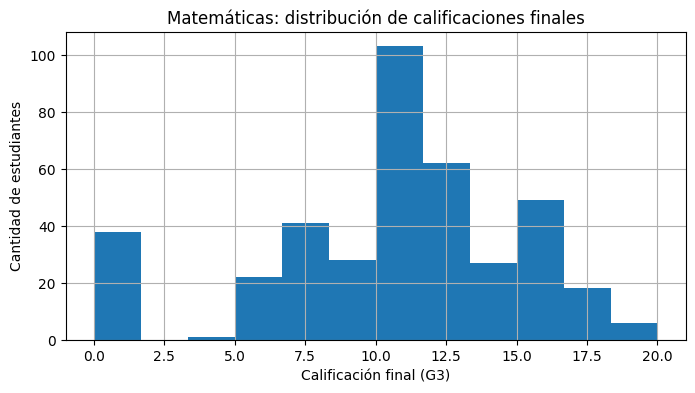

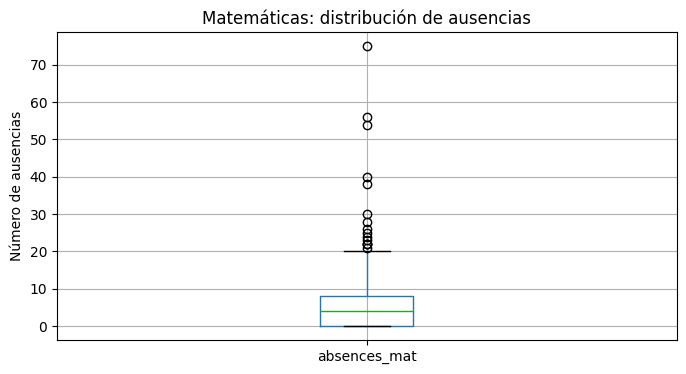

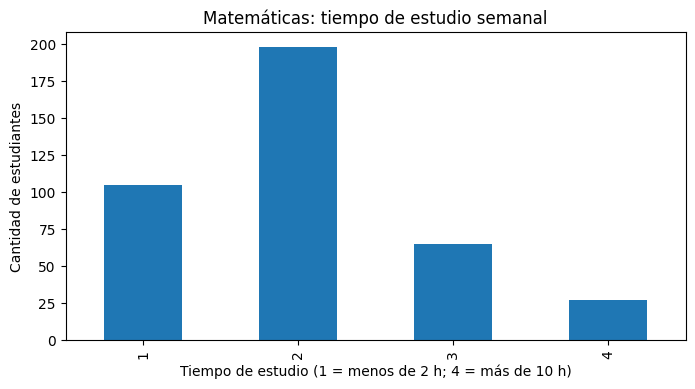


Gráficas de Portugués


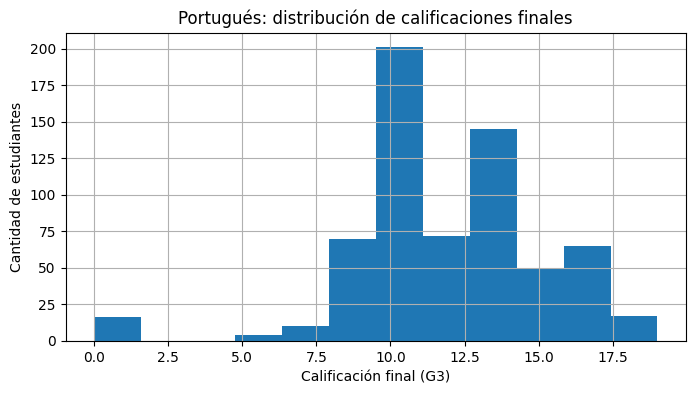

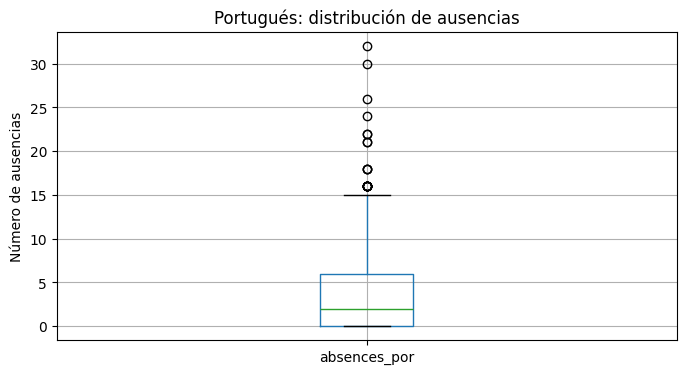

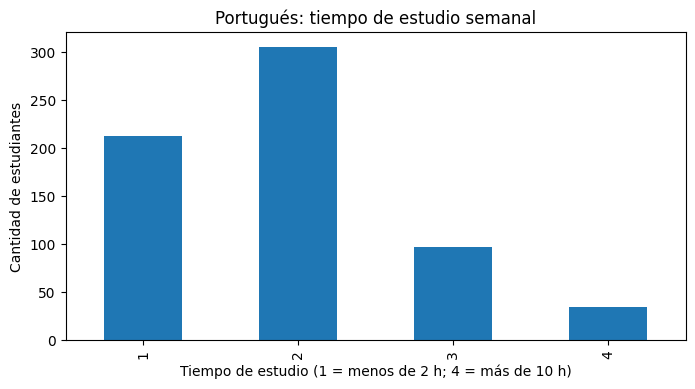

In [6]:
for asignatura, (base, sufijo) in bases.items():
    columna_g3 = f"G3_{sufijo}"
    columna_ausencias = f"absences_{sufijo}"
    columna_estudio = f"studytime_{sufijo}"

    print(f"\nGráficas de {asignatura}")

    # Gráfica 1: distribución de calificaciones finales.
    plt.figure(figsize=(8, 4))
    base[columna_g3].hist(bins=12)
    plt.title(f"{asignatura}: distribución de calificaciones finales")
    plt.xlabel("Calificación final (G3)")
    plt.ylabel("Cantidad de estudiantes")
    plt.show()

    # Gráfica 2: distribución de ausencias.
    plt.figure(figsize=(8, 4))
    base.boxplot(column=columna_ausencias)
    plt.title(f"{asignatura}: distribución de ausencias")
    plt.ylabel("Número de ausencias")
    plt.show()

    # Gráfica 3: frecuencia del tiempo de estudio.
    plt.figure(figsize=(8, 4))
    base[columna_estudio].value_counts().sort_index().plot(kind="bar")
    plt.title(f"{asignatura}: tiempo de estudio semanal")
    plt.xlabel("Tiempo de estudio (1 = menos de 2 h; 4 = más de 10 h)")
    plt.ylabel("Cantidad de estudiantes")
    plt.show()


### Hallazgos del análisis exploratorio

La siguiente celda calcula cinco hallazgos para cada asignatura. Incluye el promedio de las notas, las diferencias según el tiempo de estudio, los antecedentes de reprobación, la relación entre ausencias y calificación, y la comparación según el apoyo escolar adicional.

Al revisar los resultados, es importante fijarse tanto en los valores como en el tamaño de cada grupo. Las comparaciones ayudan a orientar el seguimiento, pero no permiten afirmar que una característica sea la causa directa de una calificación.


In [7]:
def generar_hallazgos(data, sufijo, asignatura, y_objetivo):
    col_g3 = f"G3_{sufijo}"
    col_estudio = f"studytime_{sufijo}"
    col_fallos = f"failures_{sufijo}"
    col_ausencias = f"absences_{sufijo}"
    col_apoyo = f"schoolsup_{sufijo}"

    print("\n" + "=" * 65)
    print(f"CINCO HALLAZGOS: {asignatura.upper()}")
    print("=" * 65)

    # 1. Rendimiento general y proporción de bajo rendimiento.
    promedio_g3 = data[col_g3].mean()
    mediana_g3 = data[col_g3].median()
    porcentaje_bajo = y_objetivo.mean() * 100
    print(
        f"1. Rendimiento general: el promedio de G3 es {promedio_g3:.2f}/20 "
        f"y la mediana es {mediana_g3:.2f}/20. El {porcentaje_bajo:.1f}% "
        "de los estudiantes tiene una nota inferior a 10. Este dato ayuda a dimensionar "
        "cuántos casos podrían necesitar seguimiento."
    )

    # 2. Tiempo de estudio.
    promedios_estudio = data.groupby(col_estudio)[col_g3].mean().sort_index()
    conteos_estudio = data[col_estudio].value_counts().sort_index()
    if len(promedios_estudio) >= 2:
        nivel_mayor = int(promedios_estudio.idxmax())
        nivel_menor = int(promedios_estudio.idxmin())
        print(
            f"2. Tiempo de estudio: el promedio más alto aparece en la categoría "
            f"{nivel_mayor} ({promedios_estudio.max():.2f}; n={conteos_estudio[nivel_mayor]}), "
            f"y el más bajo en la categoría {nivel_menor} "
            f"({promedios_estudio.min():.2f}; n={conteos_estudio[nivel_menor]}). "
            "La diferencia es una asociación descriptiva, no una prueba de causalidad."
        )

    # 3. Reprobaciones previas.
    sin_reprobaciones = data.loc[data[col_fallos] == 0, col_g3]
    con_reprobaciones = data.loc[data[col_fallos] > 0, col_g3]
    if len(sin_reprobaciones) and len(con_reprobaciones):
        print(
            f"3. Reprobaciones anteriores: el promedio de G3 es {sin_reprobaciones.mean():.2f} "
            f"entre quienes no registran reprobaciones (n={len(sin_reprobaciones)}) y "
            f"{con_reprobaciones.mean():.2f} entre quienes sí tienen al menos una "
            f"(n={len(con_reprobaciones)}). Este antecedente puede servir para priorizar apoyo."
        )

    # 4. Ausencias y calificación final.
    correlacion = data[col_ausencias].corr(data[col_g3])
    print(
        f"4. Ausencias y calificación: la correlación de Pearson entre ausencias y G3 "
        f"es {correlacion:.3f}. El valor describe la asociación lineal observada; "
        "por sí solo no permite concluir que las ausencias causen una nota menor."
    )

    # 5. Apoyo escolar adicional.
    if col_apoyo in data.columns:
        tabla_apoyo = data.assign(bajo_rendimiento=y_objetivo).groupby(col_apoyo).agg(
            estudiantes=(col_g3, "size"),
            promedio_G3=(col_g3, "mean"),
            porcentaje_bajo=("bajo_rendimiento", lambda s: s.mean() * 100)
        )
        print("5. Apoyo escolar adicional: comparación de promedios y bajo rendimiento según el grupo.")
        display(tabla_apoyo.round(2))
        print(
            "Esta comparación no significa que el apoyo produzca un peor resultado; "
            "puede ser que se asigne precisamente a quienes ya presentan dificultades."
        )

for asignatura, (base, sufijo) in bases.items():
    generar_hallazgos(base, sufijo, asignatura, y_por_asignatura[asignatura])



CINCO HALLAZGOS: MATEMÁTICAS
1. Rendimiento general: el promedio de G3 es 10.42/20 y la mediana es 11.00/20. El 32.9% de los estudiantes tiene una nota inferior a 10. Este dato ayuda a dimensionar cuántos casos podrían necesitar seguimiento.
2. Tiempo de estudio: el promedio más alto aparece en la categoría 3 (11.40; n=65), y el más bajo en la categoría 1 (10.05; n=105). La diferencia es una asociación descriptiva, no una prueba de causalidad.
3. Reprobaciones anteriores: el promedio de G3 es 11.25 entre quienes no registran reprobaciones (n=312) y 7.27 entre quienes sí tienen al menos una (n=83). Este antecedente puede servir para priorizar apoyo.
4. Ausencias y calificación: la correlación de Pearson entre ausencias y G3 es 0.034. El valor describe la asociación lineal observada; por sí solo no permite concluir que las ausencias causen una nota menor.
5. Apoyo escolar adicional: comparación de promedios y bajo rendimiento según el grupo.


,estudiantes,promedio_G3,porcentaje_bajo
schoolsup_mat,,,
no,344,10.56,31.1
yes,51,9.43,45.1


Esta comparación no significa que el apoyo produzca un peor resultado; puede ser que se asigne precisamente a quienes ya presentan dificultades.

CINCO HALLAZGOS: PORTUGUÉS
1. Rendimiento general: el promedio de G3 es 11.91/20 y la mediana es 12.00/20. El 15.4% de los estudiantes tiene una nota inferior a 10. Este dato ayuda a dimensionar cuántos casos podrían necesitar seguimiento.
2. Tiempo de estudio: el promedio más alto aparece en la categoría 3 (13.23; n=97), y el más bajo en la categoría 1 (10.84; n=212). La diferencia es una asociación descriptiva, no una prueba de causalidad.
3. Reprobaciones anteriores: el promedio de G3 es 12.51 entre quienes no registran reprobaciones (n=549) y 8.59 entre quienes sí tienen al menos una (n=100). Este antecedente puede servir para priorizar apoyo.
4. Ausencias y calificación: la correlación de Pearson entre ausencias y G3 es -0.091. El valor describe la asociación lineal observada; por sí solo no permite concluir que las ausencias causen una 

,estudiantes,promedio_G3,porcentaje_bajo
schoolsup_por,,,
no,581,11.98,15.83
yes,68,11.28,11.76


Esta comparación no significa que el apoyo produzca un peor resultado; puede ser que se asigne precisamente a quienes ya presentan dificultades.


## 3. Ingeniería de características y pipeline

Para preparar los datos antes de aplicar los modelos, creo tres variables que tienen sentido para el seguimiento académico: el avance entre G1 y G2, un indicador de reprobaciones anteriores y una categoría para el nivel de ausencias.

La misma función se aplica por separado a Matemáticas y Portugués. También transforma las variables categóricas y escala las ausencias. La nota final `G3` se conserva para construir el objetivo, pero no se usa como predictor, porque es precisamente el resultado que después se quiere identificar.


In [8]:
def preparar_features(data, sufijo):
    # Crea variables académicas, codifica categorías y escala ausencias.
    data = data.copy()

    col_g1 = f"G1_{sufijo}"
    col_g2 = f"G2_{sufijo}"
    col_fallos = f"failures_{sufijo}"
    col_ausencias = f"absences_{sufijo}"

    # 1. Cambio de calificación entre la primera y la segunda evaluación.
    data[f"grade_progress_{sufijo}"] = data[col_g2] - data[col_g1]

    # 2. Indicador de al menos una reprobación anterior.
    data[f"has_failures_{sufijo}"] = (data[col_fallos] > 0).astype(int)

    # 3. Clasificación del nivel de ausencias.
    data[f"absence_level_{sufijo}"] = pd.cut(
        data[col_ausencias],
        bins=[-1, 0, 5, 15, float("inf")],
        labels=["Sin ausencias", "Bajas", "Medias", "Altas"]
    )

    # Las marcas sirven para revisar calidad, no para alimentar el modelo.
    data = data.drop(
        columns=["marca_atipico_ausencias", "marca_atipico_G3"],
        errors="ignore"
    )

    # Convertir todas las variables categóricas en columnas numéricas.
    columnas_categoricas = data.select_dtypes(
        include=["object", "category"]
    ).columns.tolist()
    if columnas_categoricas:
        data = pd.get_dummies(data, columns=columnas_categoricas, dtype=int)

    # Escalado Min-Max de las ausencias.
    minimo = data[col_ausencias].min()
    maximo = data[col_ausencias].max()
    col_escalada = f"absences_scaled_{sufijo}"
    if maximo != minimo:
        data[col_escalada] = (data[col_ausencias] - minimo) / (maximo - minimo)
    else:
        data[col_escalada] = 0.0

    return data

# Aplicar el mismo proceso, por separado, a cada asignatura.
df_features_mat = preparar_features(datos, "mat")
df_features_por = preparar_features(datos_por, "por")
df_features_por_asignatura = {
    "Matemáticas": df_features_mat,
    "Portugués": df_features_por
}

for asignatura, df_transformado in df_features_por_asignatura.items():
    print(f"\n{asignatura}: dimensiones después del pipeline = {df_transformado.shape}")
    columnas_pendientes = df_transformado.select_dtypes(
        include=["object", "category"]
    ).columns.tolist()
    print("Columnas categóricas pendientes:", columnas_pendientes)

# Comprobar que la función produce el mismo resultado al ejecutarse dos veces.
for asignatura, base, sufijo, referencia in [
    ("Matemáticas", datos, "mat", df_features_mat),
    ("Portugués", datos_por, "por", df_features_por)
]:
    prueba_1 = preparar_features(base, sufijo)
    prueba_2 = preparar_features(base, sufijo)
    print(f"¿Pipeline reproducible para {asignatura}?", prueba_1.equals(prueba_2))

print("Vista previa de Matemáticas:")
display(df_features_mat.head())
print("Vista previa de Portugués:")
display(df_features_por.head())



Matemáticas: dimensiones después del pipeline = (395, 66)
Columnas categóricas pendientes: []

Portugués: dimensiones después del pipeline = (649, 66)
Columnas categóricas pendientes: []
¿Pipeline reproducible para Matemáticas? True
¿Pipeline reproducible para Portugués? True
Vista previa de Matemáticas:


,age_mat,Medu_mat,Fedu_mat,traveltime_mat,studytime_mat,failures_mat,famrel_mat,freetime_mat,goout_mat,Dalc_mat,...,higher_mat_yes,internet_mat_no,internet_mat_yes,romantic_mat_no,romantic_mat_yes,absence_level_mat_Sin ausencias,absence_level_mat_Bajas,absence_level_mat_Medias,absence_level_mat_Altas,absences_scaled_mat
0,18,4,4,2,2,0,4,3,4,1,...,1,1,0,1,0,0,0,1,0,0.080000
1,17,1,1,1,2,0,5,3,3,1,...,1,0,1,1,0,0,1,0,0,0.053333
2,15,1,1,1,2,3,4,3,2,2,...,1,0,1,1,0,0,0,1,0,0.133333
3,15,4,2,1,3,0,3,2,2,1,...,1,0,1,0,1,0,1,0,0,0.026667
4,16,3,3,1,2,0,4,3,2,1,...,1,1,0,1,0,0,1,0,0,0.053333


Vista previa de Portugués:


,age_por,Medu_por,Fedu_por,traveltime_por,studytime_por,failures_por,famrel_por,freetime_por,goout_por,Dalc_por,...,higher_por_yes,internet_por_no,internet_por_yes,romantic_por_no,romantic_por_yes,absence_level_por_Sin ausencias,absence_level_por_Bajas,absence_level_por_Medias,absence_level_por_Altas,absences_scaled_por
0,18,4,4,2,2,0,4,3,4,1,...,1,1,0,1,0,0,1,0,0,0.1250
1,17,1,1,1,2,0,5,3,3,1,...,1,0,1,1,0,0,1,0,0,0.0625
2,15,1,1,1,2,0,4,3,2,2,...,1,0,1,1,0,0,0,1,0,0.1875
3,15,4,2,1,3,0,3,2,2,1,...,1,0,1,0,1,1,0,0,0,0.0000
4,16,3,3,1,2,0,4,3,2,1,...,1,1,0,1,0,1,0,0,0,0.0000


### Preparación de la variable objetivo y de los predictores

Para cada asignatura creo una variable objetivo independiente: vale `1` cuando `G3 < 10` y `0` cuando `G3 >= 10`. La nota final se excluye de los predictores porque es el dato que el modelo debe aprender a identificar.

Como el avance académico se calcula con G1 y G2, el modelo representa una alerta que podría emitirse después de conocer la segunda evaluación y antes de conocer G3. La columna de ausencias escalada se conserva para cumplir con la preparación de datos, pero no se necesita para entrenar un árbol de decisión.


In [9]:
def preparar_xy(data_original, data_features, sufijo):
    col_g3 = f"G3_{sufijo}"
    col_escalada = f"absences_scaled_{sufijo}"
    objetivo = (data_original[col_g3] < UMBRAL_BAJO_RENDIMIENTO).astype(int)
    objetivo.name = "bajo_rendimiento"
    predictores = data_features.drop(columns=[col_g3, col_escalada], errors="ignore")

    columnas_no_numericas = predictores.select_dtypes(exclude=["number", "bool"]).columns.tolist()
    if columnas_no_numericas:
        raise TypeError(f"Quedaron columnas no numéricas en X: {columnas_no_numericas}")
    return predictores, objetivo

X_mat, y_mat = preparar_xy(datos, df_features_mat, "mat")
X_por, y_por = preparar_xy(datos_por, df_features_por, "por")

conjuntos_modelo = {
    "Matemáticas": (datos, df_features_mat, X_mat, y_mat, "mat"),
    "Portugués": (datos_por, df_features_por, X_por, y_por, "por")
}

for asignatura, (base, transformada, X_actual, y_actual, sufijo) in conjuntos_modelo.items():
    print(f"\n{asignatura}")
    print("Dimensiones de X:", X_actual.shape)
    print("Dimensiones de y:", y_actual.shape)
    print("Distribución del objetivo (0 = G3 >= 10; 1 = G3 < 10):")
    display(y_actual.value_counts().sort_index().rename(index={0: "Aprobación", 1: "Bajo rendimiento"}).to_frame("estudiantes"))
    print("¿La calificación final está dentro de X?", f"G3_{sufijo}" in X_actual.columns)
    print("¿La variable objetivo está dentro de X?", "bajo_rendimiento" in X_actual.columns)
    print("¿La columna escalada está dentro de X?", f"absences_scaled_{sufijo}" in X_actual.columns)



Matemáticas
Dimensiones de X: (395, 64)
Dimensiones de y: (395,)
Distribución del objetivo (0 = G3 >= 10; 1 = G3 < 10):


,estudiantes
bajo_rendimiento,
Aprobación,265
Bajo rendimiento,130


¿La calificación final está dentro de X? False
¿La variable objetivo está dentro de X? False
¿La columna escalada está dentro de X? False

Portugués
Dimensiones de X: (649, 64)
Dimensiones de y: (649,)
Distribución del objetivo (0 = G3 >= 10; 1 = G3 < 10):


,estudiantes
bajo_rendimiento,
Aprobación,549
Bajo rendimiento,100


¿La calificación final está dentro de X? False
¿La variable objetivo está dentro de X? False
¿La columna escalada está dentro de X? False


## 4. Segmentación y asociación

### Segmentación inicial con K-means

Aplico K-means por separado a cada asignatura. Para formar los grupos utilizo dos variables numéricas: las ausencias (`absences`) y la calificación de la segunda evaluación (`G2`). Ambas se estandarizan antes de calcular las distancias.

La nota final `G3` no participa en la creación de los grupos; la uso después para describir cómo se comporta cada segmento. Para escoger una cantidad inicial de grupos reviso el método del codo y el indicador Silhouette. La elección se interpreta como exploratoria, no como una clasificación definitiva de los estudiantes.



Método del codo: Matemáticas


,k,inercia
0,1,790.000
1,2,538.379
2,3,350.652
3,4,253.925
4,5,187.542
5,6,155.048


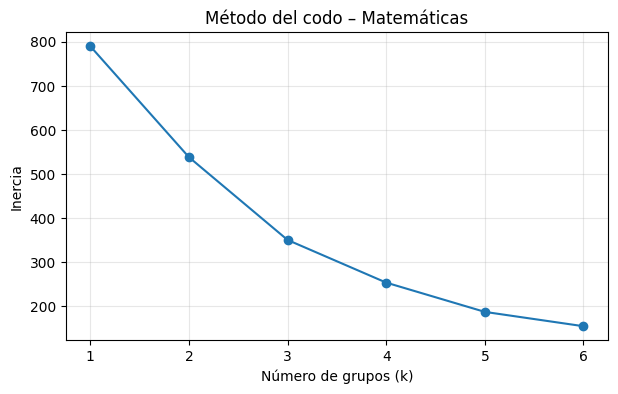

Comparación Silhouette: Matemáticas


,k,silhouette
0,4,0.417
1,3,0.400
2,5,0.399
3,6,0.373
4,2,0.347


Perfil de los grupos K-means: Matemáticas (k=4)


,estudiantes,promedio_ausencias,promedio_G2,promedio_G3,promedio_tiempo_estudio,promedio_reprobaciones,porcentaje_bajo_rendimiento
cluster,,,,,,,
0,171,2.95,13.80,13.91,2.12,0.08,0.58
1,82,14.28,9.82,9.96,1.90,0.50,41.46
2,137,2.31,7.43,6.36,2.01,0.55,67.15
3,5,52.60,10.00,9.40,2.00,0.40,60.00


Interpretación inicial de cada grupo:
- Grupo 0: 171 estudiantes, G3 promedio=13.91, ausencias promedio=2.95; 0.6% con bajo rendimiento. Este grupo presenta una proporción relativamente baja de bajo rendimiento.
- Grupo 1: 82 estudiantes, G3 promedio=9.96, ausencias promedio=14.28; 41.5% con bajo rendimiento. Este grupo presenta una proporción intermedia de bajo rendimiento.
- Grupo 2: 137 estudiantes, G3 promedio=6.36, ausencias promedio=2.31; 67.2% con bajo rendimiento. Este grupo tiene una proporción alta de bajo rendimiento.
- Grupo 3: 5 estudiantes, G3 promedio=9.40, ausencias promedio=52.60; 60.0% con bajo rendimiento. Este grupo tiene una proporción alta de bajo rendimiento.

Método del codo: Portugués


,k,inercia
0,1,1298.000
1,2,851.233
2,3,532.530
3,4,433.166
4,5,349.906
5,6,286.059


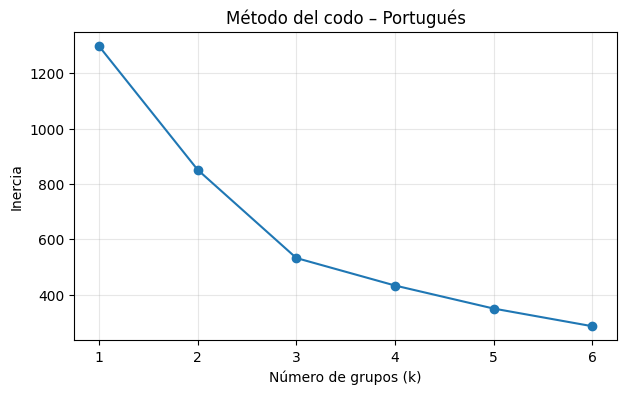

Comparación Silhouette: Portugués


,k,silhouette
0,3,0.396
1,6,0.383
2,2,0.379
3,5,0.368
4,4,0.356


Perfil de los grupos K-means: Portugués (k=3)


,estudiantes,promedio_ausencias,promedio_G2,promedio_G3,promedio_tiempo_estudio,promedio_reprobaciones,porcentaje_bajo_rendimiento
cluster,,,,,,,
0,293,2.01,13.95,14.35,2.14,0.02,0.34
1,104,11.99,10.34,10.71,1.72,0.39,24.04
2,252,2.13,9.31,9.56,1.77,0.38,29.37


Interpretación inicial de cada grupo:
- Grupo 0: 293 estudiantes, G3 promedio=14.35, ausencias promedio=2.01; 0.3% con bajo rendimiento. Este grupo presenta una proporción relativamente baja de bajo rendimiento.
- Grupo 1: 104 estudiantes, G3 promedio=10.71, ausencias promedio=11.99; 24.0% con bajo rendimiento. Este grupo presenta una proporción relativamente baja de bajo rendimiento.
- Grupo 2: 252 estudiantes, G3 promedio=9.56, ausencias promedio=2.13; 29.4% con bajo rendimiento. Este grupo presenta una proporción intermedia de bajo rendimiento.


In [10]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

def ejecutar_kmeans(data, sufijo, asignatura):
    col_aus = f"absences_{sufijo}"
    col_g2 = f"G2_{sufijo}"
    col_g3 = f"G3_{sufijo}"
    col_estudio = f"studytime_{sufijo}"
    col_fallos = f"failures_{sufijo}"

    X_segmentacion = data[[col_aus, col_g2]].copy()
    if X_segmentacion.isnull().any().any():
        raise ValueError(f"Hay valores nulos en las variables de segmentación de {asignatura}.")

    escalador = StandardScaler()
    X_escalado = escalador.fit_transform(X_segmentacion)

    # Método del codo: revisar la inercia para k de 1 a 6.
    resultados_codo = []
    for k in range(1, 7):
        modelo = KMeans(n_clusters=k, random_state=42, n_init=10)
        modelo.fit(X_escalado)
        resultados_codo.append({"k": k, "inercia": modelo.inertia_})
    tabla_codo = pd.DataFrame(resultados_codo)

    print(f"\nMétodo del codo: {asignatura}")
    display(tabla_codo.round(3))
    plt.figure(figsize=(7, 4))
    plt.plot(tabla_codo["k"], tabla_codo["inercia"], marker="o")
    plt.xlabel("Número de grupos (k)")
    plt.ylabel("Inercia")
    plt.title(f"Método del codo – {asignatura}")
    plt.xticks(range(1, 7))
    plt.grid(alpha=0.3)
    plt.show()

    # Silhouette como criterio complementario.
    resultados_silhouette = []
    for k in range(2, 7):
        modelo = KMeans(n_clusters=k, random_state=42, n_init=10)
        etiquetas = modelo.fit_predict(X_escalado)
        resultados_silhouette.append({
            "k": k,
            "silhouette": silhouette_score(X_escalado, etiquetas)
        })
    comparacion_k = pd.DataFrame(resultados_silhouette).sort_values(
        "silhouette", ascending=False
    ).reset_index(drop=True)
    print(f"Comparación Silhouette: {asignatura}")
    display(comparacion_k.round(3))

    k_elegido = int(comparacion_k.loc[0, "k"])
    modelo_final = KMeans(n_clusters=k_elegido, random_state=42, n_init=10)
    clusters = modelo_final.fit_predict(X_escalado)

    resultado = data.copy()
    resultado["cluster"] = clusters
    resultado["bajo_rendimiento"] = (resultado[col_g3] < UMBRAL_BAJO_RENDIMIENTO).astype(int)

    resumen = resultado.groupby("cluster").agg(
        estudiantes=(col_g3, "size"),
        promedio_ausencias=(col_aus, "mean"),
        promedio_G2=(col_g2, "mean"),
        promedio_G3=(col_g3, "mean"),
        promedio_tiempo_estudio=(col_estudio, "mean"),
        promedio_reprobaciones=(col_fallos, "mean"),
        porcentaje_bajo_rendimiento=("bajo_rendimiento", lambda s: s.mean() * 100)
    ).round(2)

    print(f"Perfil de los grupos K-means: {asignatura} (k={k_elegido})")
    display(resumen)
    print("Interpretación inicial de cada grupo:")
    for cluster_id, fila in resumen.iterrows():
        porcentaje = fila["porcentaje_bajo_rendimiento"]
        if porcentaje >= 50:
            lectura = "tiene una proporción alta de bajo rendimiento"
        elif porcentaje >= 25:
            lectura = "presenta una proporción intermedia de bajo rendimiento"
        else:
            lectura = "presenta una proporción relativamente baja de bajo rendimiento"
        print(
            f"- Grupo {cluster_id}: {int(fila['estudiantes'])} estudiantes, "
            f"G3 promedio={fila['promedio_G3']:.2f}, ausencias promedio={fila['promedio_ausencias']:.2f}; "
            f"{porcentaje:.1f}% con bajo rendimiento. Este grupo {lectura}."
        )

    return {
        "X_escalado": X_escalado,
        "escalador": escalador,
        "tabla_codo": tabla_codo,
        "comparacion_k": comparacion_k,
        "k_elegido": k_elegido,
        "modelo": modelo_final,
        "resultado": resultado,
        "resumen": resumen
    }

segmentaciones = {
    "Matemáticas": ejecutar_kmeans(datos, "mat", "Matemáticas"),
    "Portugués": ejecutar_kmeans(datos_por, "por", "Portugués")
}


### Cómo leer los grupos de K-means

Las tablas que aparecen en la celda anterior resumen el tamaño y el perfil académico de cada grupo. Para interpretar los resultados, me fijo en las ausencias, G2, G3, el tiempo de estudio y las reprobaciones anteriores.

Los números asignados a los grupos son etiquetas técnicas: el grupo 0 no es necesariamente mejor ni peor que el grupo 1. Además, los grupos de Matemáticas y Portugués se calculan por separado, así que sus etiquetas no se deben comparar directamente. La segmentación ayuda a explorar perfiles, pero no constituye un diagnóstico individual.


### Comparación con clustering jerárquico

Para tener un punto de comparación, aplico clustering jerárquico sobre la misma matriz estandarizada de dos variables que utilicé con K-means. Mantengo la cantidad de grupos elegida para cada asignatura y uso el método `ward`. Después reviso una tabla cruzada para ver en qué medida ambos métodos agrupan los registros de forma parecida.


In [11]:
from sklearn.cluster import AgglomerativeClustering

resultados_jerarquicos = {}
for asignatura, resultado_kmeans in segmentaciones.items():
    k = resultado_kmeans["k_elegido"]
    etiquetas_kmeans = resultado_kmeans["resultado"]["cluster"]
    etiquetas_jerarquicas = AgglomerativeClustering(
        n_clusters=k,
        linkage="ward"
    ).fit_predict(resultado_kmeans["X_escalado"])

    resultado_kmeans["resultado"]["cluster_jerarquico"] = etiquetas_jerarquicas
    tabla_cruzada = pd.crosstab(
        etiquetas_kmeans,
        etiquetas_jerarquicas,
        rownames=["K-means"],
        colnames=["Jerárquico"]
    )
    resultados_jerarquicos[asignatura] = {
        "etiquetas": etiquetas_jerarquicas,
        "tabla_cruzada": tabla_cruzada
    }

    print(f"\nComparación K-means vs. jerárquico: {asignatura}")
    display(tabla_cruzada)
    print("Cantidad de estudiantes por grupo jerárquico:")
    display(pd.Series(etiquetas_jerarquicas).value_counts().sort_index().to_frame("estudiantes"))

print("Los números de cluster son etiquetas arbitrarias; la tabla muestra coincidencias de asignación, no un orden de rendimiento.")



Comparación K-means vs. jerárquico: Matemáticas


Jerárquico,0,1,2,3
K-means,,,,
0,46,125,0,0
1,0,20,62,0
2,132,0,5,0
3,0,0,0,5


Cantidad de estudiantes por grupo jerárquico:


,estudiantes
0,178
1,145
2,67
3,5



Comparación K-means vs. jerárquico: Portugués


Jerárquico,0,1,2
K-means,,,
0,293,0,0
1,23,0,81
2,38,212,2


Cantidad de estudiantes por grupo jerárquico:


,estudiantes
0,354
1,212
2,83


Los números de cluster son etiquetas arbitrarias; la tabla muestra coincidencias de asignación, no un orden de rendimiento.


### Segmentación con DBSCAN

También pruebo DBSCAN, que forma grupos a partir de la densidad de los puntos y puede dejar algunas observaciones marcadas como ruido con la etiqueta `-1`. Lo aplico a las mismas dos variables estandarizadas de cada asignatura.

Pruebo distintos valores de `eps` con `min_samples=5` y reviso cuántos grupos aparecen y qué porcentaje queda como ruido. Si los resultados no permiten reconocer grupos claros, lo reporto como una limitación en lugar de forzar una interpretación.


In [12]:
from sklearn.cluster import DBSCAN

eps_candidatos = [0.3, 0.5, 0.7, 0.9, 1.1, 1.3, 1.5, 1.8, 2.0, 2.5]
min_samples_dbscan = 5
resultados_dbscan_por_asignatura = {}

def ejecutar_dbscan(X_escalado, asignatura):
    resultados = []
    modelos = {}

    for eps in eps_candidatos:
        modelo = DBSCAN(eps=eps, min_samples=min_samples_dbscan)
        etiquetas = modelo.fit_predict(X_escalado)
        modelos[eps] = etiquetas

        grupos = set(etiquetas) - {-1}
        cantidad_grupos = len(grupos)
        cantidad_ruido = int((etiquetas == -1).sum())
        porcentaje_ruido = cantidad_ruido / len(etiquetas) * 100

        mascara_no_ruido = etiquetas != -1
        etiquetas_sin_ruido = etiquetas[mascara_no_ruido]
        silhouette_db = np.nan
        if (cantidad_grupos >= 2 and
            2 <= len(set(etiquetas_sin_ruido)) < len(etiquetas_sin_ruido)):
            silhouette_db = silhouette_score(
                X_escalado[mascara_no_ruido], etiquetas_sin_ruido
            )

        resultados.append({
            "eps": eps,
            "cantidad_grupos": cantidad_grupos,
            "registros_ruido": cantidad_ruido,
            "porcentaje_ruido": porcentaje_ruido,
            "silhouette_sin_ruido": silhouette_db
        })

    tabla = pd.DataFrame(resultados)
    print(f"\nComparación de parámetros DBSCAN: {asignatura} (-1 = ruido)")
    display(tabla.round(3))

    soluciones_validas = tabla[
        (tabla["cantidad_grupos"] >= 2) &
        (tabla["porcentaje_ruido"] <= 50) &
        (tabla["silhouette_sin_ruido"].notna())
    ]

    if not soluciones_validas.empty:
        fila = soluciones_validas.sort_values(
            "silhouette_sin_ruido", ascending=False
        ).iloc[0]
        eps_elegido = float(fila["eps"])
        etiquetas_elegidas = modelos[eps_elegido]
        print("Valor eps seleccionado de forma preliminar:", eps_elegido)
        print("Cantidad de grupos sin contar ruido:", len(set(etiquetas_elegidas) - {-1}))
        print("Distribución de etiquetas (-1 = ruido):")
        display(pd.Series(etiquetas_elegidas).value_counts().sort_index().to_frame("estudiantes"))
    else:
        eps_elegido = None
        etiquetas_elegidas = None
        print("Con los valores probados no apareció una solución suficientemente interpretable; se registra esta limitación.")

    return {"tabla": tabla, "modelos": modelos,
            "eps_elegido": eps_elegido, "etiquetas": etiquetas_elegidas}

for asignatura, resultado_kmeans in segmentaciones.items():
    resultados_dbscan_por_asignatura[asignatura] = ejecutar_dbscan(
        resultado_kmeans["X_escalado"], asignatura
    )
    etiquetas = resultados_dbscan_por_asignatura[asignatura]["etiquetas"]
    if etiquetas is not None:
        resultado_kmeans["resultado"]["cluster_dbscan"] = etiquetas



Comparación de parámetros DBSCAN: Matemáticas (-1 = ruido)


,eps,cantidad_grupos,registros_ruido,porcentaje_ruido,silhouette_sin_ruido
0,0.3,4,27,6.835,0.165
1,0.5,2,14,3.544,0.548
2,0.7,2,9,2.278,0.541
3,0.9,2,7,1.772,0.537
4,1.1,1,4,1.013,NaN
5,1.3,1,4,1.013,NaN
6,1.5,1,3,0.759,NaN
7,1.8,1,2,0.506,NaN
8,2.0,1,2,0.506,NaN
9,2.5,1,0,0.000,NaN


Valor eps seleccionado de forma preliminar: 0.5
Cantidad de grupos sin contar ruido: 2
Distribución de etiquetas (-1 = ruido):


,estudiantes
-1,14
0,368
1,13



Comparación de parámetros DBSCAN: Portugués (-1 = ruido)


,eps,cantidad_grupos,registros_ruido,porcentaje_ruido,silhouette_sin_ruido
0,0.3,29,74,11.402,0.351
1,0.5,2,15,2.311,0.626
2,0.7,2,9,1.387,0.621
3,0.9,2,6,0.924,0.617
4,1.1,2,3,0.462,0.612
5,1.3,2,2,0.308,0.610
6,1.5,2,2,0.308,0.610
7,1.8,1,2,0.308,NaN
8,2.0,1,2,0.308,NaN
9,2.5,1,0,0.000,NaN


Valor eps seleccionado de forma preliminar: 0.5
Cantidad de grupos sin contar ruido: 2
Distribución de etiquetas (-1 = ruido):


,estudiantes
-1,15
0,627
1,7


### ¿Qué aporta cada técnica?

- **K-means:** permite fijar una cantidad de grupos y revisar perfiles a partir de las variables elegidas. En este trabajo lo uso como primera aproximación.
- **Clustering jerárquico:** permite comparar las agrupaciones con K-means y revisar si ambos métodos encuentran una estructura parecida.
- **DBSCAN:** busca zonas con mayor densidad y marca como ruido los registros que no encajan en ellas. Su resultado depende de los parámetros `eps` y `min_samples`.

No espero que las tres técnicas produzcan los mismos grupos. Lo importante es revisar qué tan interpretables son sus resultados para Matemáticas y Portugués y explicar sus diferencias.


### Lectura de los resultados de segmentación

Las tablas y gráficas anteriores muestran los resultados calculados para cada asignatura con sus propios registros. Para comparar Matemáticas y Portugués, reviso la cantidad de grupos, el tamaño de cada uno, sus promedios y la proporción de bajo rendimiento.

En K-means también tengo en cuenta el método del codo y Silhouette. En DBSCAN reviso cuántos grupos encuentra y qué porcentaje deja como ruido. Los valores de Silhouette de DBSCAN se calculan solo sobre los registros que no quedaron como ruido, por lo que no siempre son directamente comparables con los de K-means.

La interpretación final debe basarse en las tablas que se generan al ejecutar el notebook, no en números de una ejecución anterior.


## 5. Modelo predictivo y evaluación

En esta parte entreno un árbol de decisión para identificar estudiantes cuya calificación final podría quedar por debajo de 10. Repito el procedimiento por separado para Matemáticas y Portugués, usando en cada caso sus propios predictores y su propia variable objetivo.

Divido los registros en entrenamiento y prueba para comprobar el comportamiento del modelo con datos que no utilizó durante el ajuste. La nota final `G3` no entra en los predictores. Como G1 y G2 sí se utilizan, el modelo representa una alerta que se emite después de conocer la segunda evaluación y antes de conocer la nota final.


In [13]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score
)


def entrenar_y_evaluar_arbol(data_original, data_features, X, y, sufijo, asignatura):
    col_g3 = f"G3_{sufijo}"
    if col_g3 in X.columns or "bajo_rendimiento" in X.columns:
        raise AssertionError(f"Posible fuga directa en los predictores de {asignatura}.")

    # Mantener la proporción de las clases en entrenamiento y prueba.
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.30, random_state=42, stratify=y
    )
    modelo = DecisionTreeClassifier(max_depth=4, random_state=42)
    modelo.fit(X_train, y_train)

    pred_train = modelo.predict(X_train)
    pred_test = modelo.predict(X_test)
    accuracy_train = accuracy_score(y_train, pred_train)
    accuracy_test = accuracy_score(y_test, pred_test)

    matriz = confusion_matrix(y_test, pred_test, labels=[0, 1])
    precision = precision_score(y_test, pred_test, pos_label=1, zero_division=0)
    recall = recall_score(y_test, pred_test, pos_label=1, zero_division=0)
    f1 = f1_score(y_test, pred_test, pos_label=1, zero_division=0)

    clase_mayoritaria = int(y_train.mode().iloc[0])
    pred_baseline = np.full(len(y_test), clase_mayoritaria)
    accuracy_baseline = accuracy_score(y_test, pred_baseline)

    importancias = pd.Series(
        modelo.feature_importances_, index=X.columns
    ).sort_values(ascending=False)

    print("\n" + "=" * 65)
    print(f"MODELO PREDICTIVO: {asignatura}")
    print("=" * 65)
    print("Tamaño de entrenamiento:", X_train.shape)
    print("Tamaño de prueba:", X_test.shape)
    print("Accuracy de entrenamiento:", round(accuracy_train, 3))
    print("Accuracy de prueba:", round(accuracy_test, 3))
    print("Accuracy de referencia (clase mayoritaria):", round(accuracy_baseline, 3))

    print("Matriz de confusión (filas = valor real; columnas = predicción):")
    display(pd.DataFrame(
        matriz,
        index=["Real: aprobación", "Real: bajo rendimiento"],
        columns=["Predicho: aprobación", "Predicho: bajo rendimiento"]
    ))
    print("Precisión para bajo rendimiento:", round(precision, 3))
    print("Recall para bajo rendimiento:", round(recall, 3))
    print("F1 para bajo rendimiento:", round(f1, 3))
    print("15 variables más importantes según el árbol:")
    display(importancias.head(15).to_frame("importancia"))

    return {
        "X_train": X_train, "X_test": X_test,
        "y_train": y_train, "y_test": y_test,
        "modelo": modelo,
        "pred_train": pred_train, "pred_test": pred_test,
        "accuracy_train": accuracy_train, "accuracy_test": accuracy_test,
        "accuracy_baseline": accuracy_baseline,
        "matriz": matriz, "precision": precision,
        "recall": recall, "f1": f1,
        "importancias": importancias
    }


evaluaciones_modelo = {}
evaluaciones_modelo["Matemáticas"] = entrenar_y_evaluar_arbol(
    datos, df_features_mat, X_mat, y_mat, "mat", "Matemáticas"
)
evaluaciones_modelo["Portugués"] = entrenar_y_evaluar_arbol(
    datos_por, df_features_por, X_por, y_por, "por", "Portugués"
)



MODELO PREDICTIVO: Matemáticas
Tamaño de entrenamiento: (276, 64)
Tamaño de prueba: (119, 64)
Accuracy de entrenamiento: 0.953
Accuracy de prueba: 0.866
Accuracy de referencia (clase mayoritaria): 0.672
Matriz de confusión (filas = valor real; columnas = predicción):


,Predicho: aprobación,Predicho: bajo rendimiento
Real: aprobación,72,8
Real: bajo rendimiento,8,31


Precisión para bajo rendimiento: 0.795
Recall para bajo rendimiento: 0.795
F1 para bajo rendimiento: 0.795
15 variables más importantes según el árbol:


,importancia
G2_mat,0.861751
reason_mat_course,0.035425
age_mat,0.032795
freetime_mat,0.027996
Fjob_mat_other,0.024417
G1_mat,0.010290
reason_mat_reputation,0.007326
traveltime_mat,0.000000
famrel_mat,0.000000
failures_mat,0.000000



MODELO PREDICTIVO: Portugués
Tamaño de entrenamiento: (454, 64)
Tamaño de prueba: (195, 64)
Accuracy de entrenamiento: 0.958
Accuracy de prueba: 0.908
Accuracy de referencia (clase mayoritaria): 0.846
Matriz de confusión (filas = valor real; columnas = predicción):


,Predicho: aprobación,Predicho: bajo rendimiento
Real: aprobación,154,11
Real: bajo rendimiento,7,23


Precisión para bajo rendimiento: 0.676
Recall para bajo rendimiento: 0.767
F1 para bajo rendimiento: 0.719
15 variables más importantes según el árbol:


,importancia
G2_por,0.740223
G1_por,0.117053
age_por,0.039811
health_por,0.025781
school_por_MS,0.025329
goout_por,0.021314
activities_por_yes,0.016113
absences_por,0.013585
freetime_por,0.000792
famrel_por,0.000000


### Revisión de fuga de información y sobreajuste

Antes de confiar en los resultados, compruebo que la calificación final y la variable objetivo no estén dentro de los predictores. También reviso la diferencia entre el accuracy de entrenamiento y el de prueba. Si esa diferencia es grande, puede ser señal de que el árbol aprendió demasiado bien los registros de entrenamiento y no generaliza igual de bien a otros casos.

No me quedo únicamente con el porcentaje de aciertos: también reviso la matriz de confusión, la precisión, el recall y el F1 para entender qué tipo de errores comete el modelo.


In [14]:
for asignatura, evaluacion in evaluaciones_modelo.items():
    brecha = evaluacion["accuracy_train"] - evaluacion["accuracy_test"]
    matriz = evaluacion["matriz"]
    tn, fp, fn, tp = matriz.ravel()

    print("\n" + "=" * 55)
    print(f"REVISIÓN DE SOBREAJUSTE Y ERRORES: {asignatura.upper()}")
    print("=" * 55)
    print("Diferencia entre accuracy de entrenamiento y prueba:", round(brecha, 3))
    if brecha > 0.10:
        print("La brecha supera 0.10; conviene revisar si el árbol está sobreajustado.")
    else:
        print("La brecha no supera 0.10 en esta ejecución; de todas formas, se deben revisar las demás métricas.")

    print("Casos de bajo rendimiento detectados correctamente (TP):", tp)
    print("Casos de bajo rendimiento que no detectó (FN):", fn)
    print("Falsas alarmas (FP):", fp)
    print("Casos de aprobación identificados correctamente (TN):", tn)



REVISIÓN DE SOBREAJUSTE Y ERRORES: MATEMÁTICAS
Diferencia entre accuracy de entrenamiento y prueba: 0.087
La brecha no supera 0.10 en esta ejecución; de todas formas, se deben revisar las demás métricas.
Casos de bajo rendimiento detectados correctamente (TP): 31
Casos de bajo rendimiento que no detectó (FN): 8
Falsas alarmas (FP): 8
Casos de aprobación identificados correctamente (TN): 72

REVISIÓN DE SOBREAJUSTE Y ERRORES: PORTUGUÉS
Diferencia entre accuracy de entrenamiento y prueba: 0.05
La brecha no supera 0.10 en esta ejecución; de todas formas, se deben revisar las demás métricas.
Casos de bajo rendimiento detectados correctamente (TP): 23
Casos de bajo rendimiento que no detectó (FN): 7
Falsas alarmas (FP): 11
Casos de aprobación identificados correctamente (TN): 154


### Comparación de distintas profundidades del árbol

Para observar cómo cambia el modelo al aumentar su complejidad, pruebo profundidades 2, 4, 8 y sin límite (`None`) en cada asignatura. Comparo el accuracy de entrenamiento con el de prueba y reviso la brecha entre ambos.

Esta comparación sirve para identificar posibles señales de sobreajuste. La profundidad que parezca funcionar mejor debe tomarse como una referencia inicial y confirmarse con una validación adicional antes de usar el modelo en un contexto real.


In [15]:
resultados_profundidad_por_asignatura = {}

for asignatura, evaluacion in evaluaciones_modelo.items():
    X_train = evaluacion["X_train"]
    X_test = evaluacion["X_test"]
    y_train = evaluacion["y_train"]
    y_test = evaluacion["y_test"]
    resultados_profundidad = []

    for profundidad in [2, 4, 8, None]:
        arbol = DecisionTreeClassifier(max_depth=profundidad, random_state=42)
        arbol.fit(X_train, y_train)
        pred_train = arbol.predict(X_train)
        pred_test = arbol.predict(X_test)
        acc_train = accuracy_score(y_train, pred_train)
        acc_test = accuracy_score(y_test, pred_test)
        resultados_profundidad.append({
            "max_depth": "Sin límite" if profundidad is None else profundidad,
            "accuracy_entrenamiento": acc_train,
            "accuracy_prueba": acc_test,
            "brecha": acc_train - acc_test
        })

    tabla = pd.DataFrame(resultados_profundidad)
    resultados_profundidad_por_asignatura[asignatura] = tabla
    print(f"\nComparación de profundidades: {asignatura}")
    display(tabla.round(3))

    mejor = tabla.sort_values(
        ["accuracy_prueba", "brecha"], ascending=[False, True]
    ).iloc[0]
    print("Profundidad con mejor resultado de prueba en esta comparación:", mejor["max_depth"])



Comparación de profundidades: Matemáticas


,max_depth,accuracy_entrenamiento,accuracy_prueba,brecha
0,2,0.924,0.908,0.016
1,4,0.953,0.866,0.087
2,8,1.000,0.857,0.143
3,Sin límite,1.000,0.857,0.143


Profundidad con mejor resultado de prueba en esta comparación: 2

Comparación de profundidades: Portugués


,max_depth,accuracy_entrenamiento,accuracy_prueba,brecha
0,2,0.936,0.938,-0.002
1,4,0.958,0.908,0.050
2,8,1.000,0.872,0.128
3,Sin límite,1.000,0.872,0.128


Profundidad con mejor resultado de prueba en esta comparación: 2


### Interpretación del modelo predictivo

La siguiente celda reúne las métricas de los dos modelos. Al leerlas, reviso si cada árbol mejora una predicción sencilla basada en la clase mayoritaria, cuántas alertas son correctas y cuántos casos de bajo rendimiento deja pasar.

La precisión indica qué proporción de las alertas emitidas era correcta; el recall indica cuántos de los casos reales de bajo rendimiento logró detectar; y el F1 resume el equilibrio entre ambas medidas. Un resultado imperfecto también es útil si permite reconocer las limitaciones del modelo.


In [16]:
for asignatura, evaluacion in evaluaciones_modelo.items():
    brecha = evaluacion["accuracy_train"] - evaluacion["accuracy_test"]
    tn, fp, fn, tp = evaluacion["matriz"].ravel()

    print("\n" + "=" * 60)
    print(f"INTERPRETACIÓN DE LA EVALUACIÓN: {asignatura.upper()}")
    print("=" * 60)
    print(f"1. Accuracy de prueba: {evaluacion['accuracy_test']:.3f}; referencia simple: {evaluacion['accuracy_baseline']:.3f}.")
    if evaluacion["accuracy_test"] > evaluacion["accuracy_baseline"]:
        print("   El árbol supera la referencia simple en esta partición.")
    elif evaluacion["accuracy_test"] == evaluacion["accuracy_baseline"]:
        print("   El árbol obtiene el mismo accuracy que la referencia simple.")
    else:
        print("   El árbol no supera la referencia simple en esta partición.")
    print(f"2. Precisión: {evaluacion['precision']:.3f}.")
    print(f"3. Recall: {evaluacion['recall']:.3f}.")
    print(f"4. F1: {evaluacion['f1']:.3f}.")
    print(f"5. Brecha entrenamiento-prueba: {brecha:.3f}.")
    print(f"6. Errores: {fn} falsos negativos y {fp} falsos positivos.")
    print("7. La comparación de profundidades sirve para revisar la complejidad, pero conviene confirmarla con validación cruzada.")
    print("El árbol puede servir como apoyo para priorizar seguimiento; no debe reemplazar la valoración de docentes.")



INTERPRETACIÓN DE LA EVALUACIÓN: MATEMÁTICAS
1. Accuracy de prueba: 0.866; referencia simple: 0.672.
   El árbol supera la referencia simple en esta partición.
2. Precisión: 0.795.
3. Recall: 0.795.
4. F1: 0.795.
5. Brecha entrenamiento-prueba: 0.087.
6. Errores: 8 falsos negativos y 8 falsos positivos.
7. La comparación de profundidades sirve para revisar la complejidad, pero conviene confirmarla con validación cruzada.
El árbol puede servir como apoyo para priorizar seguimiento; no debe reemplazar la valoración de docentes.

INTERPRETACIÓN DE LA EVALUACIÓN: PORTUGUÉS
1. Accuracy de prueba: 0.908; referencia simple: 0.846.
   El árbol supera la referencia simple en esta partición.
2. Precisión: 0.676.
3. Recall: 0.767.
4. F1: 0.719.
5. Brecha entrenamiento-prueba: 0.050.
6. Errores: 7 falsos negativos y 11 falsos positivos.
7. La comparación de profundidades sirve para revisar la complejidad, pero conviene confirmarla con validación cruzada.
El árbol puede servir como apoyo para prio

### Resultados del modelo en las dos asignaturas

Los resultados de Matemáticas y Portugués se calculan en las tablas anteriores, usando una partición estratificada de entrenamiento y prueba para cada archivo. En cada caso se muestran el accuracy, la comparación con una referencia sencilla, la matriz de confusión, la precisión, el recall, el F1 y la diferencia entre entrenamiento y prueba.

No copio aquí cifras fijas porque pueden cambiar si se modifica el archivo o la partición de los datos. Para el informe final se deben tomar los valores que aparecen en la última ejecución del notebook y explicar qué significan para cada asignatura.

El modelo es una herramienta de apoyo para reconocer posibles casos que requieren seguimiento. No debe utilizarse para etiquetar definitivamente a un estudiante ni para tomar decisiones académicas sin revisión humana.


## 6. Detección de anomalías y experimentación — Unidad 7

### Ruta elegida: Isolation Forest

Para esta parte elegí Isolation Forest porque permite revisar datos numéricos sin necesitar una columna de texto libre ni una estructura de transacciones. La misma prueba se realiza por separado en Matemáticas y Portugués.

Busco identificar combinaciones poco habituales de ausencias y calificaciones de las dos primeras evaluaciones. Que el algoritmo marque un registro como anomalía no quiere decir que esté mal capturado ni que el estudiante tenga bajo rendimiento; solo indica que esa combinación se aparta del patrón que encontró el modelo.

En cada base utilizo `absences`, `G1` y `G2`. Dejo por fuera `G3` porque es la calificación final. Comparo tres valores de `contamination` (0.05, 0.10 y 0.15), manteniendo `n_estimators=200` y `random_state=42` para que el experimento sea reproducible. Este parámetro controla el umbral del algoritmo; no representa una tasa real conocida de errores.


In [17]:
from sklearn.ensemble import IsolationForest

columnas_anomalias_por_asignatura = {
    "Matemáticas": ["absences_mat", "G1_mat", "G2_mat"],
    "Portugués": ["absences_por", "G1_por", "G2_por"]
}

X_anomalias_por_asignatura = {}
for asignatura, (base, sufijo) in bases.items():
    columnas = columnas_anomalias_por_asignatura[asignatura]
    faltantes = [col for col in columnas if col not in base.columns]
    if faltantes:
        raise KeyError(f"Faltan columnas para Isolation Forest en {asignatura}: {faltantes}")

    X_anomalias = base[columnas].copy()
    if X_anomalias.isnull().any().any():
        raise ValueError(f"Hay valores nulos en las variables de anomalías de {asignatura}.")
    if not all(pd.api.types.is_numeric_dtype(X_anomalias[col]) for col in columnas):
        raise TypeError(f"Las variables de Isolation Forest deben ser numéricas ({asignatura}).")

    X_anomalias_por_asignatura[asignatura] = X_anomalias
    print(f"\nVariables utilizadas en {asignatura}:", columnas)
    print("Dimensiones de la matriz:", X_anomalias.shape)
    display(X_anomalias.describe().round(2))



Variables utilizadas en Matemáticas: ['absences_mat', 'G1_mat', 'G2_mat']
Dimensiones de la matriz: (395, 3)


,absences_mat,G1_mat,G2_mat
count,395.00,395.00,395.00
mean,5.71,10.91,10.71
std,8.00,3.32,3.76
min,0.00,3.00,0.00
25%,0.00,8.00,9.00
50%,4.00,11.00,11.00
75%,8.00,13.00,13.00
max,75.00,19.00,19.00



Variables utilizadas en Portugués: ['absences_por', 'G1_por', 'G2_por']
Dimensiones de la matriz: (649, 3)


,absences_por,G1_por,G2_por
count,649.00,649.00,649.00
mean,3.66,11.40,11.57
std,4.64,2.75,2.91
min,0.00,0.00,0.00
25%,0.00,10.00,10.00
50%,2.00,11.00,11.00
75%,6.00,13.00,13.00
max,32.00,19.00,19.00


### Comparación de las tres configuraciones

Para que la comparación sea justa dentro de cada asignatura, mantengo las mismas variables, el mismo número de estimadores y la misma semilla aleatoria. Lo único que cambio es `contamination`: 5 %, 10 % y 15 %.

Isolation Forest no necesita el escalado por distancia que se usa en K-means, así que trabajo con las variables numéricas originales. Los resultados de cada archivo se calculan de manera independiente.


In [18]:
configuraciones_contamination = [0.05, 0.10, 0.15]
resultados_iforest = []
resultados_iforest_por_asignatura = {}

for asignatura, X_anomalias in X_anomalias_por_asignatura.items():
    predicciones = {}
    modelos = {}
    filas_resultado = []

    for contamination in configuraciones_contamination:
        modelo_if = IsolationForest(
            n_estimators=200,
            contamination=contamination,
            random_state=42
        )
        etiquetas = modelo_if.fit_predict(X_anomalias)
        predicciones[contamination] = etiquetas
        modelos[contamination] = modelo_if

        cantidad_anomalias = int((etiquetas == -1).sum())
        porcentaje_observado = cantidad_anomalias / len(X_anomalias) * 100
        fila = {
            "asignatura": asignatura,
            "contamination_configurada": contamination,
            "estudiantes_evaluados": len(X_anomalias),
            "anomalias_detectadas": cantidad_anomalias,
            "porcentaje_detectado": porcentaje_observado
        }
        filas_resultado.append(fila)
        resultados_iforest.append(fila)

    resultados_iforest_por_asignatura[asignatura] = {
        "predicciones": predicciones,
        "modelos": modelos,
        "comparacion": pd.DataFrame(filas_resultado)
    }

comparacion_iforest = pd.DataFrame(resultados_iforest)
print("Comparación de ejecuciones de Isolation Forest en las dos bases:")
display(comparacion_iforest.round(2))

# Usar el escenario intermedio para revisar los registros marcados.
contamination_referencia = 0.10
datos_anomalias_por_asignatura = {}

for asignatura, (base, sufijo) in bases.items():
    resultado_if = resultados_iforest_por_asignatura[asignatura]
    etiquetas_referencia = resultado_if["predicciones"][contamination_referencia]
    modelo_referencia = resultado_if["modelos"][contamination_referencia]
    X_anomalias = X_anomalias_por_asignatura[asignatura]

    datos_anomalias = base.copy()
    datos_anomalias["etiqueta_iforest_10"] = etiquetas_referencia
    datos_anomalias["es_anomalia_iforest_10"] = datos_anomalias["etiqueta_iforest_10"].eq(-1)
    datos_anomalias["score_iforest_10"] = modelo_referencia.score_samples(X_anomalias)
    datos_anomalias_por_asignatura[asignatura] = datos_anomalias

    print(f"\nDistribución de casos marcados con contamination=0.10: {asignatura}")
    display(datos_anomalias["es_anomalia_iforest_10"].value_counts().rename(
        index={True: "Anomalía", False: "Normal"}
    ).to_frame("cantidad"))


Comparación de ejecuciones de Isolation Forest en las dos bases:


,asignatura,contamination_configurada,estudiantes_evaluados,anomalias_detectadas,porcentaje_detectado
0,Matemáticas,0.05,395,20,5.06
1,Matemáticas,0.10,395,39,9.87
2,Matemáticas,0.15,395,60,15.19
3,Portugués,0.05,649,33,5.08
4,Portugués,0.10,649,65,10.02
5,Portugués,0.15,649,97,14.95



Distribución de casos marcados con contamination=0.10: Matemáticas


,cantidad
es_anomalia_iforest_10,
Normal,356
Anomalía,39



Distribución de casos marcados con contamination=0.10: Portugués


,cantidad
es_anomalia_iforest_10,
Normal,584
Anomalía,65


### Revisión de los registros marcados

Para mirar con más detalle los resultados, tomo el escenario intermedio (`contamination=0.10`) en cada asignatura. Esta elección facilita la revisión, pero no significa que el 10 % de los estudiantes sean anomalías reales.

Conservo todos los registros originales y agrego una marca y un puntaje para facilitar su inspección. Los casos que señala el algoritmo deben revisarse con su contexto antes de pensar en cualquier acción académica.



Perfil de los grupos con contamination=0.10: Matemáticas


,estudiantes,promedio_ausencias,mediana_ausencias,promedio_G1,promedio_G2,promedio_G3
grupo_iforest,,,,,,
Anomalía,39,13.77,6.0,11.44,9.54,9.51
Normal,356,4.83,4.0,10.85,10.84,10.51


Casos más aislados para revisión humana: Matemáticas


,absences_mat,G1_mat,G2_mat,score_iforest_10
276,75,10,9,-0.723136
74,54,11,12,-0.691895
183,56,9,9,-0.672034
198,24,18,18,-0.670013
137,0,4,0,-0.664557
47,4,19,19,-0.659664
260,21,17,18,-0.646868
315,40,13,11,-0.644899
130,0,12,0,-0.639474
374,0,19,18,-0.631327


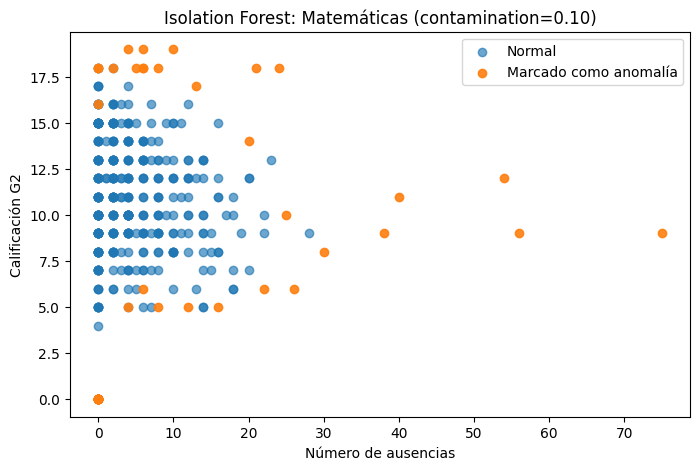


Perfil de los grupos con contamination=0.10: Portugués


,estudiantes,promedio_ausencias,mediana_ausencias,promedio_G1,promedio_G2,promedio_G3
grupo_iforest,,,,,,
Anomalía,65,8.77,6.0,10.83,10.46,10.65
Normal,584,3.09,2.0,11.46,11.69,12.05


Casos más aislados para revisión humana: Portugués


,absences_por,G1_por,G2_por,score_iforest_10
567,0,4,0,-0.729115
197,32,14,13,-0.728414
212,30,14,15,-0.720068
603,0,5,0,-0.708785
605,0,5,0,-0.708785
256,26,7,8,-0.667874
597,0,9,0,-0.666366
572,8,5,5,-0.663080
155,22,9,7,-0.658959
610,0,8,0,-0.657546


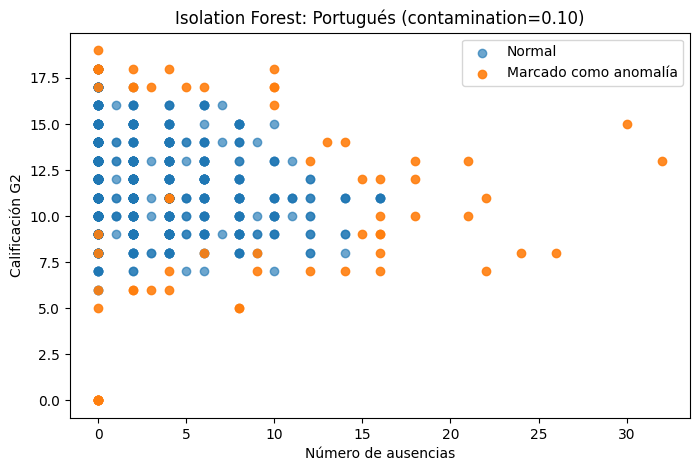

In [19]:
resumen_iforest_por_asignatura = {}
casos_marcados_por_asignatura = {}

for asignatura, (base, sufijo) in bases.items():
    datos_anomalias = datos_anomalias_por_asignatura[asignatura]
    columnas = columnas_anomalias_por_asignatura[asignatura]
    col_g1 = f"G1_{sufijo}"
    col_g2 = f"G2_{sufijo}"
    col_aus = f"absences_{sufijo}"
    col_g3 = f"G3_{sufijo}"

    resumen = (
        datos_anomalias
        .assign(grupo_iforest=lambda d: np.where(d["es_anomalia_iforest_10"], "Anomalía", "Normal"))
        .groupby("grupo_iforest")
        .agg(
            estudiantes=(col_g2, "size"),
            promedio_ausencias=(col_aus, "mean"),
            mediana_ausencias=(col_aus, "median"),
            promedio_G1=(col_g1, "mean"),
            promedio_G2=(col_g2, "mean"),
            promedio_G3=(col_g3, "mean")
        )
        .round(2)
    )
    resumen_iforest_por_asignatura[asignatura] = resumen
    print(f"\nPerfil de los grupos con contamination=0.10: {asignatura}")
    display(resumen)

    casos = (
        datos_anomalias.loc[
            datos_anomalias["es_anomalia_iforest_10"],
            columnas + ["score_iforest_10"]
        ]
        .sort_values("score_iforest_10", ascending=True)
    )
    casos_marcados_por_asignatura[asignatura] = casos
    print(f"Casos más aislados para revisión humana: {asignatura}")
    display(casos.head(15))

    # La visualización muestra ausencias y G2; el modelo utiliza también G1.
    mascara = datos_anomalias["es_anomalia_iforest_10"]
    plt.figure(figsize=(8, 5))
    plt.scatter(
        datos_anomalias.loc[~mascara, col_aus],
        datos_anomalias.loc[~mascara, col_g2],
        label="Normal", alpha=0.65
    )
    plt.scatter(
        datos_anomalias.loc[mascara, col_aus],
        datos_anomalias.loc[mascara, col_g2],
        label="Marcado como anomalía", alpha=0.9
    )
    plt.title(f"Isolation Forest: {asignatura} (contamination=0.10)")
    plt.xlabel("Número de ausencias")
    plt.ylabel("Calificación G2")
    plt.legend()
    plt.show()


### Interpretación del experimento

La siguiente celda resume cuántos registros quedaron marcados con cada configuración y compara el perfil promedio del grupo señalado con el grupo normal. Reviso los resultados de Matemáticas y Portugués por separado.

Es importante no confundir una anomalía con un error de captura o con bajo rendimiento. Isolation Forest no cuenta con una etiqueta verdadera que permita calcular precisión o recall para estas anomalías. Por eso, la salida sirve para orientar una revisión, no para tomar decisiones automáticamente.


In [20]:
for asignatura, resultado_if in resultados_iforest_por_asignatura.items():
    print("\n" + "=" * 60)
    print(f"INTERPRETACIÓN DE ISOLATION FOREST: {asignatura.upper()}")
    print("=" * 60)
    tabla = resultado_if["comparacion"].sort_values("contamination_configurada")
    for _, fila in tabla.iterrows():
        print(
            f"- contamination={fila['contamination_configurada']:.0%}: "
            f"{int(fila['anomalias_detectadas'])} de {int(fila['estudiantes_evaluados'])} registros "
            f"marcados ({fila['porcentaje_detectado']:.1f}%)."
        )

    resumen = resumen_iforest_por_asignatura[asignatura]
    print("Comparación de perfiles (contamination=10%):")
    if {"Anomalía", "Normal"}.issubset(set(resumen.index)):
        for variable, etiqueta in [
            ("promedio_ausencias", "ausencias promedio"),
            ("promedio_G1", "G1 promedio"),
            ("promedio_G2", "G2 promedio"),
            ("promedio_G3", "G3 promedio")
        ]:
            valor_anomalia = resumen.loc["Anomalía", variable]
            valor_normal = resumen.loc["Normal", variable]
            print(f"- {etiqueta}: grupo marcado={valor_anomalia:.2f}; grupo normal={valor_normal:.2f}.")
    else:
        print("No fue posible comparar ambos grupos en esta ejecución.")

print("\nEstas diferencias describen los registros marcados; no prueban que sean errores ni que representen bajo rendimiento. Cada caso necesita revisión humana.")



INTERPRETACIÓN DE ISOLATION FOREST: MATEMÁTICAS
- contamination=5%: 20 de 395 registros marcados (5.1%).
- contamination=10%: 39 de 395 registros marcados (9.9%).
- contamination=15%: 60 de 395 registros marcados (15.2%).
Comparación de perfiles (contamination=10%):
- ausencias promedio: grupo marcado=13.77; grupo normal=4.83.
- G1 promedio: grupo marcado=11.44; grupo normal=10.85.
- G2 promedio: grupo marcado=9.54; grupo normal=10.84.
- G3 promedio: grupo marcado=9.51; grupo normal=10.51.

INTERPRETACIÓN DE ISOLATION FOREST: PORTUGUÉS
- contamination=5%: 33 de 649 registros marcados (5.1%).
- contamination=10%: 65 de 649 registros marcados (10.0%).
- contamination=15%: 97 de 649 registros marcados (14.9%).
Comparación de perfiles (contamination=10%):
- ausencias promedio: grupo marcado=8.77; grupo normal=3.09.
- G1 promedio: grupo marcado=10.83; grupo normal=11.46.
- G2 promedio: grupo marcado=10.46; grupo normal=11.69.
- G3 promedio: grupo marcado=10.65; grupo normal=12.05.

Estas d

### Resultados y cierre de la Unidad 7

En esta práctica apliqué Isolation Forest a las dos bases, cada una con sus propios registros y con las variables de ausencias, G1 y G2. La tabla de comparación muestra qué cantidad de observaciones marca el algoritmo cuando se configura `contamination` en 5 %, 10 % y 15 %.

Los resultados de Matemáticas y Portugués no se deben mezclar como si fueran las mismas personas. Lo que sí puedo comparar es la cantidad y el porcentaje de casos marcados en cada asignatura, además de las diferencias entre los perfiles normales y los señalados por el modelo.

Como no existe una etiqueta real que indique cuáles registros son anomalías, no es posible afirmar que todos los casos marcados sean errores. La decisión más responsable es conservar los datos, revisar los casos con contexto y utilizar el resultado únicamente como apoyo para el análisis académico.

*Los valores exactos se generan al ejecutar las celdas anteriores con los dos archivos CSV. Si se reemplaza alguno de los archivos, es necesario revisar nuevamente las tablas y las interpretaciones.*
